# Recursive FLUX re-noise sampling without retraining

This Modal notebook tests whether the saved 12-epoch overfitting checkpoint
can refine its own outputs when a completed latent is partially re-noised and
integrated back to `t=0` with the same frozen NVARC conditioning.

Success criteria:

- reproduce the existing linear 50-step baseline with matched seeds;
- compare restart times `0.25`, `0.50`, and `0.80` for up to five rounds;
- report every round independently without target-based selection or voting;
- record transformer evaluations, runtime, valid-grid, shape, cell-accuracy,
  and exact-grid results;
- inspect raw VAE images and strictly decoded ARC grids inline;
- perform no training and never modify model weights.


In [1]:
!nvidia-smi

Tue Aug 25 20:32:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.95.05              Driver Version: 580.95.05      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H200                    On  |   00000000:D8:00.0 Off |                    0 |
| N/A   31C    P0             77W /  700W |       4MiB / 143771MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
%uv pip uninstall torchvision

Using Python 3.12.6 environment at: /usr/local
Uninstalled 1 package in 43ms
 - torchvision==0.23.0+cu129
Note: you may need to restart the kernel to use updated packages.


## 1. Fixed run and checkpoint configuration

The checkpoint path is explicit because the training report failed during Modal
Volume finalization and therefore has no saved_checkpoint entry. The validation
below accepts only the known completed 12-epoch run and inspects the standalone
transformer files directly.


In [3]:
from __future__ import annotations

import base64
from dataclasses import asdict, replace
from datetime import datetime, timezone
import hashlib
import importlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import shutil
import subprocess
import sys
import time

TRAINING_RUN_ID = '20260825T150620231361Z'
CHECKPOINT_DIRECTORY_NAME = (
    '.flux-transformer-step-2496.partial-c9c70c21fb254c55a9f6fcf4544df352'
)
SOURCE_REVISION = '58c31c495be8c7fa04cc9ee29b491ba175568e81'
EXPECTED_GLOBAL_STEP = 2496
EXPECTED_COMPLETED_EPOCHS = 12
EXPECTED_TASKS = 8
MINIMUM_VRAM_GIB = 70.0
REPOSITORY_URL = 'https://github.com/joshuakauling/diffusion-arc.git'

VOLUME_ROOT = Path('/mnt/diffusion-arc-models')
BASE_FLUX_CHECKPOINT = VOLUME_ROOT / 'flux2-klein-base-4b'
NVARC_CHECKPOINT = VOLUME_ROOT / 'nvarc-qwen3-4b-grids15-sft139'
MODEL_MANIFEST = VOLUME_ROOT / 'download-manifest.json'
ARC_DATA_ROOT = VOLUME_ROOT / 'data' / 'raw' / 'arc-agi-2'
ARC_DATA_MANIFEST = VOLUME_ROOT / 'data' / 'arc-agi-2-manifest.json'
TRAINING_RUN_ROOT = (
    VOLUME_ROOT
    / 'results'
    / 'single-gpu-overfitting-pilot'
    / TRAINING_RUN_ID
)
TRAINING_REPORT_PATH = TRAINING_RUN_ROOT / 'report.json'
TRANSFORMER_CHECKPOINT = TRAINING_RUN_ROOT / CHECKPOINT_DIRECTORY_NAME

required_paths = (
    BASE_FLUX_CHECKPOINT,
    NVARC_CHECKPOINT,
    MODEL_MANIFEST,
    ARC_DATA_ROOT,
    ARC_DATA_MANIFEST,
    TRAINING_REPORT_PATH,
    TRANSFORMER_CHECKPOINT,
)
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f'Missing required Volume artifacts: {missing_paths}')
if not TRANSFORMER_CHECKPOINT.is_dir():
    raise NotADirectoryError(TRANSFORMER_CHECKPOINT)

EVALUATION_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT_ROOT = (
    TRAINING_RUN_ROOT / 'restart-sampling-comparisons' / EVALUATION_ID
)


def run_command(
    label: str,
    command: list[str],
    *,
    cwd: Path | None = None,
    env: dict[str, str] | None = None,
) -> str:
    completed = subprocess.run(
        command,
        cwd=cwd,
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )
    if completed.returncode != 0:
        tail = '\n'.join(completed.stdout.splitlines()[-40:])
        if tail:
            print(tail)
        raise RuntimeError(f'{label} failed with exit code {completed.returncode}')
    return completed.stdout.strip()


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


print('Training report:', TRAINING_REPORT_PATH)
print('Transformer checkpoint:', TRANSFORMER_CHECKPOINT)
print('Optional output directory:', OUTPUT_ROOT)


Training report: /mnt/diffusion-arc-models/results/single-gpu-overfitting-pilot/20260825T150620231361Z/report.json
Transformer checkpoint: /mnt/diffusion-arc-models/results/single-gpu-overfitting-pilot/20260825T150620231361Z/.flux-transformer-step-2496.partial-c9c70c21fb254c55a9f6fcf4544df352
Optional output directory: /mnt/diffusion-arc-models/results/single-gpu-overfitting-pilot/20260825T150620231361Z/restart-sampling-comparisons/20260825T203225808608Z


## 2. Fetch and test the exact source revision

Run this setup cell once. Reexecuting it in the same kernel reuses the verified
source checkout. A GitHub token must be attached through a Modal Secret.


In [4]:
SOURCE_DIR = Path('/tmp') / f'diffusion-arc-restart-eval-{EVALUATION_ID}'
if not SOURCE_DIR.exists():
    SOURCE_DIR.mkdir(parents=True)
    run_command('git init', ['git', 'init'], cwd=SOURCE_DIR)
    run_command(
        'add origin',
        ['git', 'remote', 'add', 'origin', REPOSITORY_URL],
        cwd=SOURCE_DIR,
    )

    github_token = os.environ.get('GITHUB_TOKEN', '').strip()
    if not github_token:
        raise RuntimeError('Attach a Modal Secret containing GITHUB_TOKEN')
    credential = base64.b64encode(
        f'x-access-token:{github_token}'.encode('utf-8')
    ).decode('ascii')
    git_environment = os.environ.copy()
    git_environment.pop('GITHUB_TOKEN', None)
    git_environment.update({
        'GIT_TERMINAL_PROMPT': '0',
        'GIT_CONFIG_COUNT': '1',
        'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
        'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {credential}',
    })
    try:
        run_command(
            'fetch source',
            ['git', 'fetch', '--depth=1', 'origin', SOURCE_REVISION],
            cwd=SOURCE_DIR,
            env=git_environment,
        )
        run_command(
            'checkout source',
            ['git', 'checkout', '--detach', 'FETCH_HEAD'],
            cwd=SOURCE_DIR,
        )
    finally:
        git_environment.clear()
        del git_environment
        del credential

RESOLVED_SOURCE_COMMIT = run_command(
    'resolve source', ['git', 'rev-parse', 'HEAD'], cwd=SOURCE_DIR
)
if RESOLVED_SOURCE_COMMIT != SOURCE_REVISION:
    raise RuntimeError(
        f'Resolved source {RESOLVED_SOURCE_COMMIT} differs from {SOURCE_REVISION}'
    )

PINNED_PACKAGES = {
    'accelerate': '1.12.0',
    'diffusers': '0.39.0',
    'einops': '0.8.1',
    'matplotlib': '3.10.6',
    'Pillow': '11.3.0',
    'safetensors': '0.8.0',
    'torch': '2.13.0',
    'tqdm': '4.67.1',
    'transformers': '4.56.1',
}


def installed_version(name: str) -> str | None:
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


requirements = [
    f'{name}=={version}'
    for name, version in PINNED_PACKAGES.items()
    if installed_version(name) != version
]
if requirements:
    run_command(
        'install pinned dependencies',
        [
            sys.executable,
            '-m',
            'pip',
            'install',
            '--quiet',
            '--no-input',
            '--no-cache-dir',
            *requirements,
        ],
    )
run_command(
    'install Diffusion-ARC source',
    [
        sys.executable,
        '-m',
        'pip',
        'install',
        '--quiet',
        '--no-input',
        '--no-deps',
        '--no-build-isolation',
        '-e',
        str(SOURCE_DIR),
    ],
)

source_path = str((SOURCE_DIR / 'src').resolve())
if source_path not in sys.path:
    sys.path.insert(0, source_path)
importlib.invalidate_caches()
import diffusion_arc

test_environment = os.environ.copy()
test_environment['PYTHONDONTWRITEBYTECODE'] = '1'
test_environment['PYTHONPATH'] = source_path
test_started = time.perf_counter()
test_process = subprocess.run(
    [sys.executable, '-B', '-m', 'unittest', 'discover', '-s', 'tests'],
    cwd=SOURCE_DIR,
    env=test_environment,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False,
)
print('\n'.join(test_process.stdout.splitlines()[-30:]))
if test_process.returncode != 0:
    raise RuntimeError(f'Unit tests returned {test_process.returncode}')
print('Evaluation source:', RESOLVED_SOURCE_COMMIT)
print(f'Unit tests: PASS in {time.perf_counter() - test_started:.2f}s')


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
....................................................................................................................../usr/local/lib/python3.12/site-packages/torch/nn/functional.py:3006: UserWarning: Mismatch dtype between input and weight: input dtype = c10::BFloat16, weight dtype = float, Cannot dispatch to fused implementation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/layer_norm.cpp:346.)
  return torch.rms_norm(input, normalized_shape, weight, eps)
..................................
----------------------------------------------------------------------
Ran 152 tests in 3.827s

OK
Evaluation source: 58c31c495be8c7fa04cc9ee29b491ba175568e81
Unit tests: PASS in 16.

## 3. Validate GPU, run provenance, dataset, split, and checkpoint

The failed training status is accepted only when all recorded failures belong
to checkpoint finalization after 12 completed epochs. The Safetensors index and
every shard header must agree before any model is loaded.


In [5]:
import torch
from safetensors import safe_open

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable')
if not torch.cuda.is_bf16_supported():
    raise RuntimeError('Selected CUDA device does not support BF16')
DEVICE = torch.device('cuda:0')
torch.cuda.set_device(DEVICE)
properties = torch.cuda.get_device_properties(DEVICE)
gpu_vram_gib = properties.total_memory / 2**30
if gpu_vram_gib < MINIMUM_VRAM_GIB:
    raise RuntimeError(
        f'Requires at least {MINIMUM_VRAM_GIB:.0f} GiB VRAM; '
        f'received {properties.name} with {gpu_vram_gib:.1f} GiB'
    )


def cuda_memory(label: str) -> dict[str, object]:
    torch.cuda.synchronize(DEVICE)
    return {
        'label': label,
        'allocated_gib': torch.cuda.memory_allocated(DEVICE) / 2**30,
        'reserved_gib': torch.cuda.memory_reserved(DEVICE) / 2**30,
        'peak_allocated_gib': torch.cuda.max_memory_allocated(DEVICE) / 2**30,
        'peak_reserved_gib': torch.cuda.max_memory_reserved(DEVICE) / 2**30,
    }


training_report = json.loads(TRAINING_REPORT_PATH.read_text(encoding='utf-8'))
if training_report.get('completed_optimizer_steps') != EXPECTED_GLOBAL_STEP:
    raise RuntimeError('Training report has an unexpected optimizer-step count')
if training_report.get('completed_epochs') != EXPECTED_COMPLETED_EPOCHS:
    raise RuntimeError('Training report has an unexpected completed-epoch count')
if training_report.get('status') == 'FAIL':
    failures = training_report.get('failures')
    if not isinstance(failures, list) or not failures:
        raise RuntimeError('Failed training report contains no failure records')
    if any(item.get('stage') != 'checkpoint-finalization' for item in failures):
        raise RuntimeError('Training failed outside checkpoint finalization')
    print('Accepted known report failure: checkpoint finalization only')
elif training_report.get('status') != 'COMPLETE':
    raise RuntimeError(f'Unexpected training status: {training_report.get("status")!r}')

if training_report['source']['resolved_commit'] != SOURCE_REVISION:
    raise RuntimeError('Evaluation source differs from the training source')
if sha256_file(MODEL_MANIFEST) != training_report['model_manifest_sha256']:
    raise RuntimeError('Model manifest differs from the training run')
if sha256_file(ARC_DATA_MANIFEST) != training_report['dataset']['manifest_sha256']:
    raise RuntimeError('Dataset manifest differs from the training run')

model_manifest = json.loads(MODEL_MANIFEST.read_text(encoding='utf-8'))
if Path(model_manifest['flux']['path']).resolve() != BASE_FLUX_CHECKPOINT.resolve():
    raise RuntimeError('FLUX base checkpoint differs from the model manifest')
if Path(model_manifest['nvarc']['path']).resolve() != NVARC_CHECKPOINT.resolve():
    raise RuntimeError('NVARC checkpoint differs from the model manifest')

dataset_manifest = json.loads(ARC_DATA_MANIFEST.read_text(encoding='utf-8'))
for task_id in training_report['dataset']['task_ids']:
    relative = f'training/{task_id}.json'
    task_path = ARC_DATA_ROOT / relative
    expected_hash = dataset_manifest['files'].get(relative)
    if expected_hash is None or not task_path.is_file():
        raise RuntimeError(f'Dataset manifest lacks selected task: {relative}')
    if sha256_file(task_path) != expected_hash:
        raise RuntimeError(f'Selected raw task differs: {relative}')

TEMP_DATA_ROOT = Path('/tmp') / f'diffusion-arc-restart-data-{EVALUATION_ID}' / 'data'
RUNTIME_SPLIT_ROOT = TEMP_DATA_ROOT / 'splits' / 'overfitting_run_1'
if not RUNTIME_SPLIT_ROOT.exists():
    RUNTIME_SPLIT_ROOT.parent.mkdir(parents=True)
    shutil.copytree(
        SOURCE_DIR / 'data' / 'splits' / 'overfitting_run_1',
        RUNTIME_SPLIT_ROOT,
    )
raw_root = TEMP_DATA_ROOT / 'raw'
raw_root.mkdir(exist_ok=True)
raw_link = raw_root / 'arc-agi-2'
if not raw_link.exists():
    os.symlink(ARC_DATA_ROOT, raw_link, target_is_directory=True)

actual_split_hashes = {
    str(path.relative_to(RUNTIME_SPLIT_ROOT)): sha256_file(path)
    for path in sorted(RUNTIME_SPLIT_ROOT.rglob('*.json'))
}
if actual_split_hashes != training_report['dataset']['split_file_sha256']:
    raise RuntimeError('Evaluation split files differ from the training run')


def validate_transformer_checkpoint(directory: Path) -> dict[str, object]:
    config_path = directory / 'config.json'
    if not config_path.is_file():
        raise FileNotFoundError(f'Missing transformer config: {config_path}')
    config = json.loads(config_path.read_text(encoding='utf-8'))
    if not isinstance(config, dict) or not config:
        raise RuntimeError('Transformer config is empty or invalid')

    index_paths = sorted(directory.glob('*.safetensors.index.json'))
    if len(index_paths) != 1:
        raise RuntimeError(
            f'Expected exactly one Safetensors index, found {len(index_paths)}'
        )
    index_path = index_paths[0]
    index = json.loads(index_path.read_text(encoding='utf-8'))
    weight_map = index.get('weight_map')
    if not isinstance(weight_map, dict) or not weight_map:
        raise RuntimeError('Safetensors index has no weight_map')

    shard_names = sorted(set(weight_map.values()))
    if any(not isinstance(name, str) or Path(name).name != name for name in shard_names):
        raise RuntimeError('Safetensors index contains an unsafe shard path')
    missing_shards = [name for name in shard_names if not (directory / name).is_file()]
    if missing_shards:
        raise FileNotFoundError(f'Missing checkpoint shards: {missing_shards}')

    tensors_by_shard = {
        shard_name: {name for name, mapped in weight_map.items() if mapped == shard_name}
        for shard_name in shard_names
    }
    total_bytes = 0
    for shard_name in shard_names:
        shard_path = directory / shard_name
        if shard_path.stat().st_size <= 0:
            raise RuntimeError(f'Checkpoint shard is empty: {shard_name}')
        total_bytes += shard_path.stat().st_size
        with safe_open(shard_path, framework='pt', device='cpu') as handle:
            actual_keys = set(handle.keys())
        if actual_keys != tensors_by_shard[shard_name]:
            raise RuntimeError(f'Shard tensor map differs: {shard_name}')

    expected_names = {'config.json', index_path.name, *shard_names}
    extra_files = sorted(
        path.name for path in directory.iterdir()
        if path.is_file() and path.name not in expected_names
    )
    return {
        'path': str(directory),
        'index': index_path.name,
        'shards': shard_names,
        'tensor_count': len(weight_map),
        'total_bytes': total_bytes,
        'extra_files': extra_files,
    }


CHECKPOINT_MANIFEST = validate_transformer_checkpoint(TRANSFORMER_CHECKPOINT)

from diffusion_arc.training.config import load_single_gpu_training_config

source_config = load_single_gpu_training_config(
    SOURCE_DIR / 'configs' / 'training' / 'single_gpu_overfitting_pilot_v2.json'
)
RUN_CONFIG = replace(
    source_config,
    models=replace(
        source_config.models,
        flux_checkpoint=BASE_FLUX_CHECKPOINT,
        nvarc_checkpoint=NVARC_CHECKPOINT,
    ),
    data=replace(source_config.data, split_directory=RUNTIME_SPLIT_ROOT),
)
TASK_IDS = tuple(training_report['dataset']['task_ids'])
if len(TASK_IDS) != EXPECTED_TASKS:
    raise RuntimeError(f'Expected {EXPECTED_TASKS} tasks, received {len(TASK_IDS)}')

print(f'GPU: {properties.name} | {gpu_vram_gib:.1f} GiB')
print(
    f'Checkpoint: {len(CHECKPOINT_MANIFEST["shards"])} shards, '
    f'{CHECKPOINT_MANIFEST["tensor_count"]} tensors, '
    f'{CHECKPOINT_MANIFEST["total_bytes"] / 2**30:.2f} GiB'
)
if CHECKPOINT_MANIFEST['extra_files']:
    print('Ignored non-model files:', CHECKPOINT_MANIFEST['extra_files'])


Accepted known report failure: checkpoint finalization only
GPU: NVIDIA H200 | 139.8 GiB
Checkpoint: 9 shards, 169 tensors, 14.44 GiB


## 4. Load the frozen inference stack once

NVARC, the VAE, and the saved transformer are frozen. No optimizer is created.
Do not rerun this cell when changing only the lower interactive configuration.


In [6]:
from diffusion_arc.training.single_gpu_setup import (
    load_single_gpu_models,
    prepare_single_gpu_device,
    seed_single_gpu_process,
)

os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

device = prepare_single_gpu_device(RUN_CONFIG)
seed_single_gpu_process(167)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(device)

load_started = time.perf_counter()
models = load_single_gpu_models(
    RUN_CONFIG,
    device=device,
    transformer_checkpoint=TRANSFORMER_CHECKPOINT,
)
models.transformer.requires_grad_(False)
models.transformer.eval()
load_seconds = time.perf_counter() - load_started

if any(parameter.requires_grad for parameter in models.nvarc_runner.parameters()):
    raise RuntimeError('NVARC unexpectedly trainable')
if any(parameter.requires_grad for parameter in models.vae_decoder.parameters()):
    raise RuntimeError('VAE unexpectedly trainable')
if any(parameter.requires_grad for parameter in models.transformer.parameters()):
    raise RuntimeError('Evaluation transformer unexpectedly trainable')

MODEL_LOAD_SUMMARY = {
    'load_seconds': load_seconds,
    'transformer_parameters': sum(
        parameter.numel() for parameter in models.transformer.parameters()
    ),
    'memory': cuda_memory('after-model-load'),
}
MODEL_LOAD_SUMMARY


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/9 [00:00<?, ?it/s]

{'load_seconds': 17.676022599999996,
 'transformer_parameters': 3875544576,
 'memory': {'label': 'after-model-load',
  'allocated_gib': 21.522281169891357,
  'reserved_gib': 21.564453125,
  'peak_allocated_gib': 21.522281169891357,
  'peak_reserved_gib': 21.564453125}}

## 5. Reconstruct the exact V2 evaluation panels

The keys come from the training report. For every selected key, the target-free
evaluation tokens must equal the exact prefix preceding the final training
target. NVARC conditioning is cached lazily per panel and task selection.


In [7]:
from diffusion_arc.arc_data import (
    ArcEvaluationTask,
    ArcQuery,
    apply_training_augmentation,
    load_training_task,
    render_evaluation_prompts,
    tokenize_nvarc_evaluation_sample,
)
from diffusion_arc.inference import prepare_evaluation_text_inputs
from diffusion_arc.training import ArcTrainingDataset

PANEL_VIEWS = {
    'seen_training_augmentation': 'train',
    'canonical_original': 'train_original',
    'unseen_augmentation': 'train_unseen',
}


def build_panel_prompts(panel_name: str) -> dict[str, object]:
    view_name = PANEL_VIEWS[panel_name]
    dataset = ArcTrainingDataset(
        split_directory=RUNTIME_SPLIT_ROOT,
        view_name=view_name,
        tokenizer=models.tokenizer,
    )
    keys_to_indices = {str(key): index for index, key in enumerate(dataset.keys)}
    expected_entry = training_report['evaluation_panels'][panel_name]
    expected_keys = tuple(expected_entry['keys'])

    samples = []
    expected_grids = []
    task_ids = []
    token_counts = []
    for serialized_key in expected_keys:
        if serialized_key not in keys_to_indices:
            raise RuntimeError(f'Reported key is absent from {view_name}: {serialized_key}')
        index = keys_to_indices[serialized_key]
        key = dataset.keys[index]
        training_sample = dataset[index]
        raw_task = load_training_task(dataset.source_directory / f'{key.task_id}.json')
        augmented = apply_training_augmentation(raw_task, key.augmentation)
        query_pair = augmented.pairs[-1]
        evaluation_task = ArcEvaluationTask(
            task_id=serialized_key,
            demonstrations=augmented.pairs[:-1],
            queries=(ArcQuery(query_index=0, input_grid=query_pair.input_grid),),
        )
        rendered = render_evaluation_prompts(evaluation_task)[0]
        tokenized = tokenize_nvarc_evaluation_sample(
            rendered,
            models.tokenizer,
            max_tokens=dataset.max_tokens,
        )
        training_prefix = training_sample.input_ids[:training_sample.prefix_token_ends[-1]]
        if tokenized.input_ids != training_prefix:
            raise RuntimeError(f'Evaluation tokens differ from training prefix: {key}')
        if training_sample.target_grids[-1] != query_pair.output_grid:
            raise RuntimeError(f'Expected target differs from training sample: {key}')

        samples.append(tokenized)
        expected_grids.append(query_pair.output_grid)
        task_ids.append(key.task_id)
        token_counts.append(len(tokenized.input_ids))

    if tuple(task_ids) != TASK_IDS:
        raise RuntimeError(f'{panel_name} task order differs from the training report')
    if tuple(token_counts) != tuple(expected_entry['target_free_token_counts']):
        raise RuntimeError(f'{panel_name} token counts differ from the training report')
    return {
        'panel_name': panel_name,
        'view_name': view_name,
        'keys': expected_keys,
        'task_ids': tuple(task_ids),
        'samples': tuple(samples),
        'expected_grids': tuple(expected_grids),
        'token_counts': tuple(token_counts),
    }


PANEL_PROMPTS = {
    name: build_panel_prompts(name)
    for name in PANEL_VIEWS
}
CONDITIONING_CACHE: dict[tuple[str, tuple[str, ...]], dict[str, object]] = {}


def get_conditioned_panel(
    panel_name: str,
    selected_task_ids: tuple[str, ...],
) -> dict[str, object]:
    if panel_name not in PANEL_PROMPTS:
        raise ValueError(f'Unknown panel: {panel_name}')
    panel = PANEL_PROMPTS[panel_name]
    available = tuple(panel['task_ids'])
    if selected_task_ids:
        unknown = tuple(task_id for task_id in selected_task_ids if task_id not in available)
        if unknown:
            raise ValueError(f'Unknown task IDs for {panel_name}: {unknown}')
        chosen = tuple(task_id for task_id in available if task_id in selected_task_ids)
    else:
        chosen = available
    cache_key = (panel_name, chosen)
    if cache_key in CONDITIONING_CACHE:
        return CONDITIONING_CACHE[cache_key]

    indices = tuple(available.index(task_id) for task_id in chosen)
    conditioned = {
        'panel_name': panel_name,
        'task_ids': chosen,
        'keys': tuple(panel['keys'][index] for index in indices),
        'expected_grids': tuple(panel['expected_grids'][index] for index in indices),
        'text_inputs': prepare_evaluation_text_inputs(
            tuple(panel['samples'][index] for index in indices),
            nvarc_runner=models.nvarc_runner,
        ),
    }
    CONDITIONING_CACHE[cache_key] = conditioned
    return conditioned


{name: panel['keys'] for name, panel in PANEL_PROMPTS.items()}


{'seen_training_augmentation': ('3c9b0459_ID_1290374658_4,1,2,3,0',
  '0d3d703e_ID_7458913620_3,0,4,2,1',
  '8be77c9e_ID_6921504738_1,2,3,0',
  'c9e6f938_ID_7809641352_0,1,3,2',
  '00576224_ID_6095374821_1,0,2',
  '0520fde7_ID_4960851372_2,0,1,3',
  '88a62173_ID_1984750623_2,0,1,3',
  'd631b094_ID_0487193526_2,4,0,1,3'),
 'canonical_original': ('3c9b0459_ID_0123456789_0,1,2,3,4',
  '0d3d703e_ID_0123456789_0,1,2,3,4',
  '8be77c9e_ID_0123456789_0,1,2,3',
  'c9e6f938_ID_0123456789_0,1,2,3',
  '00576224_ID_0123456789_0,1,2',
  '0520fde7_ID_0123456789_0,1,2,3',
  '88a62173_ID_0123456789_0,1,2,3',
  'd631b094_ID_0123456789_0,1,2,3,4'),
 'unseen_augmentation': ('3c9b0459_ID_5896310427_4,2,1,0,3',
  '0d3d703e_ID_4912687530_0,3,4,1,2',
  '8be77c9e_ID_9741652038_1,0,3,2',
  'c9e6f938_ID_2675430198_3,2,1,0',
  '00576224_ID_0378942156_0,2,1',
  '0520fde7_ID_2830971546_0,2,1,3',
  '88a62173_ID_6017325489_2,3,0,1',
  'd631b094_ID_7169453802_4,1,0,3,2')}

## 6. Define the notebook-local restart sampler

The repository sampler intentionally requires a complete `t=1 -> 0` schedule.
This experiment therefore defines a local Euler integrator that also accepts a
partial `restart_t -> 0` schedule. No repository source code is changed.

For the straight flow path, a completed prediction `z_hat` is re-noised as

`z_restart = (1 - restart_t) * z_hat + restart_t * epsilon`.

Every restart branch begins from the exact same baseline latent. At a given
round, all restart-time branches use the same newly sampled standard-normal
tensor, derived deterministically from the generation seed and round number.


In [8]:
from collections.abc import Sequence

from diffusion_arc.arc_data.decoding import classify_arc_cells, decode_arc_grids
from diffusion_arc.inference import (
    ArcGenerationBatch,
    diagnose_exact_grids,
    generate_arc_batch,
    linear_timestep_schedule,
)
from diffusion_arc.model import TARGET_LATENT_SHAPE
from diffusion_arc.model.flux_execution import (
    build_flux_image_position_ids,
    flux_transformer_device,
    predict_flux_velocity,
)

IMAGE_SEQUENCE_LENGTH = TARGET_LATENT_SHAPE[0]


def restart_interval_count(restart_t: float, base_num_steps: int) -> int:
    if isinstance(restart_t, bool) or not isinstance(restart_t, (int, float)):
        raise TypeError('restart_t must be numeric')
    restart_t = float(restart_t)
    if not 0.0 < restart_t < 1.0:
        raise ValueError('restart_t must be strictly between zero and one')
    if (
        isinstance(base_num_steps, bool)
        or not isinstance(base_num_steps, int)
        or base_num_steps <= 0
    ):
        raise ValueError('base_num_steps must be a positive integer')
    return max(1, math.ceil(restart_t * base_num_steps))


def build_restart_schedule(
    restart_t: float,
    base_num_steps: int,
    *,
    device: torch.device | None,
) -> torch.Tensor:
    interval_count = restart_interval_count(restart_t, base_num_steps)
    schedule = torch.linspace(
        float(restart_t),
        0.0,
        steps=interval_count + 1,
        device=device,
        dtype=torch.float32,
    )
    if (
        not math.isclose(
            schedule[0].item(),
            float(restart_t),
            rel_tol=0.0,
            abs_tol=1e-7,
        )
        or schedule[-1].item() != 0.0
    ):
        raise RuntimeError('Restart schedule endpoints are incorrect')
    if not bool((schedule[:-1] > schedule[1:]).all().item()):
        raise RuntimeError('Restart schedule is not strictly decreasing')
    return schedule


def renoise_latents(
    completed_latents: torch.Tensor,
    *,
    restart_t: float,
    noise: torch.Tensor,
) -> torch.Tensor:
    if completed_latents.shape != noise.shape:
        raise ValueError('Completed latents and noise must have identical shapes')
    if completed_latents.device != noise.device:
        raise ValueError('Completed latents and noise must use the same device')
    if completed_latents.dtype != noise.dtype:
        raise ValueError('Completed latents and noise must use the same dtype')
    if not 0.0 < float(restart_t) < 1.0:
        raise ValueError('restart_t must be strictly between zero and one')
    return (1.0 - float(restart_t)) * completed_latents + float(restart_t) * noise


def integrate_restart_latents(
    initial_latents: torch.Tensor,
    text_inputs,
    *,
    timestep_schedule: torch.Tensor | Sequence[float],
) -> torch.Tensor:
    transformer_device = flux_transformer_device(models.transformer)
    schedule = torch.as_tensor(
        timestep_schedule,
        device=transformer_device,
        dtype=torch.float32,
    )
    if schedule.ndim != 1 or schedule.numel() < 2:
        raise ValueError('Restart schedule must have at least two values')
    if not bool(torch.isfinite(schedule).all().item()):
        raise ValueError('Restart schedule must contain finite values')
    if not 0.0 < schedule[0].item() <= 1.0 or schedule[-1].item() != 0.0:
        raise ValueError('Restart schedule must run from (0, 1] to zero')
    if not bool((schedule[:-1] > schedule[1:]).all().item()):
        raise ValueError('Restart schedule must be strictly decreasing')

    latents = initial_latents.to(
        device=transformer_device,
        dtype=torch.float32,
    )
    if tuple(latents.shape[1:]) != TARGET_LATENT_SHAPE:
        raise ValueError(f'Expected latent shape [B, {TARGET_LATENT_SHAPE}]')
    batch_size = latents.shape[0]
    if text_inputs.encoder_hidden_states.shape[0] != batch_size:
        raise ValueError('Latent and conditioning batches differ')
    image_position_ids = build_flux_image_position_ids(
        batch_size,
        transformer_device,
    )

    previous_training_mode = models.transformer.training
    models.transformer.eval()
    try:
        with torch.inference_mode():
            for timestep, next_timestep in zip(
                schedule[:-1],
                schedule[1:],
                strict=True,
            ):
                velocity = predict_flux_velocity(
                    models.transformer,
                    latents,
                    text_inputs,
                    image_position_ids,
                    timestep.expand(batch_size),
                    compute_dtype=models.flux_compute_dtype,
                )
                delta = (next_timestep - timestep).to(dtype=latents.dtype)
                latents = latents + delta * velocity.to(dtype=latents.dtype)
    finally:
        models.transformer.train(previous_training_mode)
    return latents


def normalized_images_to_uint8(images: torch.Tensor) -> torch.Tensor:
    return (
        images.detach()
        .to(device='cpu', dtype=torch.float32)
        .clamp(-1.0, 1.0)
        .add(1.0)
        .mul(127.5)
        .round()
        .to(dtype=torch.uint8)
    )


def decode_restart_latents(
    latents: torch.Tensor,
    expected_grids,
) -> dict[str, object]:
    previous_training_mode = models.vae_decoder.training
    models.vae_decoder.eval()
    try:
        with torch.inference_mode():
            decoded_images = models.vae_decoder(latents)
    finally:
        models.vae_decoder.train(previous_training_mode)
    rgb_images = normalized_images_to_uint8(decoded_images)
    class_canvases = classify_arc_cells(rgb_images)
    predictions = decode_arc_grids(class_canvases)
    diagnostics = diagnose_exact_grids(predictions, expected_grids)
    return {
        'final_latents': latents.detach().to(
            device='cpu', dtype=torch.float32
        ).clone(),
        'rgb_images': rgb_images,
        'class_canvases': class_canvases,
        'predictions': predictions,
        'diagnostics': diagnostics,
    }


for restart_t, expected_intervals in ((0.25, 13), (0.50, 25), (0.80, 40)):
    smoke_schedule = build_restart_schedule(
        restart_t,
        50,
        device=None,
    )
    assert smoke_schedule.numel() == expected_intervals + 1
    assert math.isclose(
        smoke_schedule[0].item(),
        restart_t,
        rel_tol=0.0,
        abs_tol=1e-7,
    )
    assert smoke_schedule[-1].item() == 0.0

smoke_clean = torch.ones((1, 2, 3), dtype=torch.float32)
smoke_noise = torch.zeros_like(smoke_clean)
torch.testing.assert_close(
    renoise_latents(smoke_clean, restart_t=0.25, noise=smoke_noise),
    torch.full_like(smoke_clean, 0.75),
)
print('Restart sampler smoke checks: PASS')


Restart sampler smoke checks: PASS


## 7. Interactive restart configuration

Edit and rerun this cell, then rerun the preview, inference, aggregation,
and display cells. An empty `ACTIVE_TASK_IDS` tuple selects all eight tasks.

`MAX_RESTART_ROUNDS = 5` means one normal baseline generation followed by
five re-noise-and-denoise rounds for every configured restart time.


In [9]:
ACTIVE_PANEL_NAMES = ('seen_training_augmentation',)
ACTIVE_TASK_IDS: tuple[str, ...] = ()
BASE_NUM_STEPS = 50
ACTIVE_RESTART_TIMES = (0.25, 0.50, 0.80)
MAX_RESTART_ROUNDS = 5
ACTIVE_GENERATION_SEEDS = (167, 168)

# False reuses completed rounds from the in-memory cache.
FORCE_RERUN = False

# Saving writes only JSON and PNG outputs; it never calls modal.Volume.commit().
SAVE_RESULTS = True

if not ACTIVE_PANEL_NAMES or len(set(ACTIVE_PANEL_NAMES)) != len(ACTIVE_PANEL_NAMES):
    raise ValueError('ACTIVE_PANEL_NAMES must be non-empty and unique')
if any(name not in PANEL_VIEWS for name in ACTIVE_PANEL_NAMES):
    raise ValueError(f'Unknown panel selection: {ACTIVE_PANEL_NAMES}')
if len(set(ACTIVE_TASK_IDS)) != len(ACTIVE_TASK_IDS):
    raise ValueError('ACTIVE_TASK_IDS must be unique')
if isinstance(BASE_NUM_STEPS, bool) or not isinstance(BASE_NUM_STEPS, int) or BASE_NUM_STEPS <= 0:
    raise ValueError('BASE_NUM_STEPS must be a positive integer')
if not ACTIVE_RESTART_TIMES or len(set(ACTIVE_RESTART_TIMES)) != len(ACTIVE_RESTART_TIMES):
    raise ValueError('ACTIVE_RESTART_TIMES must be non-empty and unique')
for restart_t in ACTIVE_RESTART_TIMES:
    build_restart_schedule(restart_t, BASE_NUM_STEPS, device=None)
if (
    isinstance(MAX_RESTART_ROUNDS, bool)
    or not isinstance(MAX_RESTART_ROUNDS, int)
    or MAX_RESTART_ROUNDS <= 0
):
    raise ValueError('MAX_RESTART_ROUNDS must be a positive integer')
if not ACTIVE_GENERATION_SEEDS or len(set(ACTIVE_GENERATION_SEEDS)) != len(ACTIVE_GENERATION_SEEDS):
    raise ValueError('ACTIVE_GENERATION_SEEDS must be non-empty and unique')

restart_intervals = {
    restart_t: restart_interval_count(restart_t, BASE_NUM_STEPS)
    for restart_t in ACTIVE_RESTART_TIMES
}
estimated_transformer_evaluations = (
    len(ACTIVE_PANEL_NAMES)
    * len(ACTIVE_GENERATION_SEEDS)
    * (
        BASE_NUM_STEPS
        + MAX_RESTART_ROUNDS * sum(restart_intervals.values())
    )
)
print('Panels:', ACTIVE_PANEL_NAMES)
print('Tasks:', ACTIVE_TASK_IDS or TASK_IDS)
print('Base steps:', BASE_NUM_STEPS)
print('Restart intervals:', restart_intervals)
print('Maximum restart rounds:', MAX_RESTART_ROUNDS)
print('Seeds:', ACTIVE_GENERATION_SEEDS)
print('Estimated transformer evaluations:', estimated_transformer_evaluations)


Panels: ('seen_training_augmentation',)
Tasks: ('3c9b0459', '0d3d703e', '8be77c9e', 'c9e6f938', '00576224', '0520fde7', '88a62173', 'd631b094')
Base steps: 50
Restart intervals: {0.25: 13, 0.5: 25, 0.8: 40}
Maximum restart rounds: 5
Seeds: (167, 168)
Estimated transformer evaluations: 880


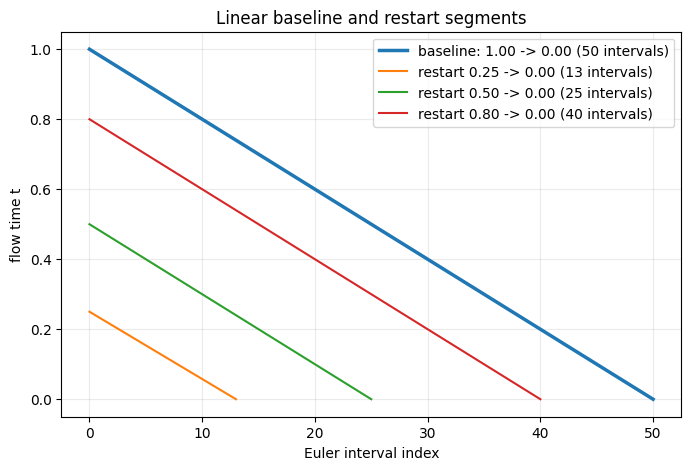

In [10]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(8, 5))
base_schedule = linear_timestep_schedule(BASE_NUM_STEPS).cpu()
axis.plot(
    range(base_schedule.numel()),
    base_schedule.numpy(),
    label=f'baseline: 1.00 -> 0.00 ({BASE_NUM_STEPS} intervals)',
    linewidth=2.5,
)
for restart_t in ACTIVE_RESTART_TIMES:
    schedule = build_restart_schedule(
        restart_t,
        BASE_NUM_STEPS,
        device=None,
    ).cpu()
    axis.plot(
        range(schedule.numel()),
        schedule.numpy(),
        label=(
            f'restart {restart_t:.2f} -> 0.00 '
            f'({schedule.numel() - 1} intervals)'
        ),
    )
axis.set_title('Linear baseline and restart segments')
axis.set_xlabel('Euler interval index')
axis.set_ylabel('flow time t')
axis.grid(alpha=0.25)
axis.legend()
plt.show()


## 8. Run or extend the restart cache

The baseline is generated once per panel and seed and shared by all restart
branches. Each branch is then advanced sequentially, so round `r+1` starts
from that branch's round `r` output.

The target grids are used only after decoding to compute diagnostics. They do
not influence re-noising, integration, stopping, or sample selection.


In [11]:
from tqdm.auto import tqdm

if 'BASELINE_CACHE' not in globals():
    BASELINE_CACHE: dict[tuple[object, ...], dict[str, object]] = {}
if 'RESTART_CACHE' not in globals():
    RESTART_CACHE: dict[tuple[object, ...], dict[str, object]] = {}


def baseline_cache_key(
    panel_name: str,
    task_ids: tuple[str, ...],
    seed: int,
) -> tuple[object, ...]:
    return (
        str(TRANSFORMER_CHECKPOINT),
        panel_name,
        task_ids,
        BASE_NUM_STEPS,
        seed,
    )


def restart_cache_key(
    panel_name: str,
    task_ids: tuple[str, ...],
    restart_t: float,
    round_index: int,
    seed: int,
) -> tuple[object, ...]:
    return (
        str(TRANSFORMER_CHECKPOINT),
        panel_name,
        task_ids,
        BASE_NUM_STEPS,
        float(restart_t),
        round_index,
        seed,
    )


def restart_noise_seed(generation_seed: int, round_index: int) -> int:
    return generation_seed * 1_000_003 + round_index * 97_409 + 31


progress_total = (
    len(ACTIVE_PANEL_NAMES)
    * len(ACTIVE_GENERATION_SEEDS)
    * (1 + len(ACTIVE_RESTART_TIMES) * MAX_RESTART_ROUNDS)
)
progress = tqdm(total=progress_total, desc='Restart inference', unit='state')

for panel_name in ACTIVE_PANEL_NAMES:
    conditioned = get_conditioned_panel(panel_name, ACTIVE_TASK_IDS)
    chosen_task_ids = tuple(conditioned['task_ids'])
    for seed in ACTIVE_GENERATION_SEEDS:
        base_key = baseline_cache_key(panel_name, chosen_task_ids, seed)
        progress.set_postfix_str(f'{panel_name} | baseline | seed {seed}')
        if base_key not in BASELINE_CACHE or FORCE_RERUN:
            torch.cuda.reset_peak_memory_stats(device)
            started = time.perf_counter()
            baseline = generate_arc_batch(
                models.transformer,
                models.vae_decoder,
                conditioned['text_inputs'],
                timestep_schedule=linear_timestep_schedule(
                    BASE_NUM_STEPS,
                    device=device,
                ),
                compute_dtype=models.flux_compute_dtype,
                generator=torch.Generator(device=device).manual_seed(seed),
            )
            baseline_seconds = time.perf_counter() - started
            BASELINE_CACHE[base_key] = {
                'panel_name': panel_name,
                'task_ids': chosen_task_ids,
                'keys': tuple(conditioned['keys']),
                'expected_grids': tuple(conditioned['expected_grids']),
                'base_num_steps': BASE_NUM_STEPS,
                'seed': seed,
                'round_index': 0,
                'restart_t': None,
                'segment_intervals': BASE_NUM_STEPS,
                'cumulative_transformer_evaluations': BASE_NUM_STEPS,
                'seconds': baseline_seconds,
                'cumulative_seconds': baseline_seconds,
                'final_latents': baseline.final_latents,
                'rgb_images': baseline.rgb_images,
                'class_canvases': baseline.class_canvases,
                'predictions': baseline.predictions,
                'diagnostics': diagnose_exact_grids(
                    baseline.predictions,
                    conditioned['expected_grids'],
                ),
                'memory': cuda_memory(
                    f'{panel_name}-baseline-seed-{seed}'
                ),
            }
        progress.update(1)

        base_entry = BASELINE_CACHE[base_key]
        for restart_t in ACTIVE_RESTART_TIMES:
            previous_latents = base_entry['final_latents'].to(
                device=device,
                dtype=torch.float32,
            )
            cumulative_seconds = float(base_entry['seconds'])
            segment_schedule = build_restart_schedule(
                restart_t,
                BASE_NUM_STEPS,
                device=device,
            )
            segment_intervals = segment_schedule.numel() - 1

            for round_index in range(1, MAX_RESTART_ROUNDS + 1):
                progress.set_postfix_str(
                    f'{panel_name} | t={restart_t:.2f} | '
                    f'round {round_index} | seed {seed}'
                )
                cache_key = restart_cache_key(
                    panel_name,
                    chosen_task_ids,
                    restart_t,
                    round_index,
                    seed,
                )
                if cache_key in RESTART_CACHE and not FORCE_RERUN:
                    cached = RESTART_CACHE[cache_key]
                    previous_latents = cached['final_latents'].to(
                        device=device,
                        dtype=torch.float32,
                    )
                    cumulative_seconds = float(cached['cumulative_seconds'])
                    progress.update(1)
                    continue

                noise_generator = torch.Generator(device=device).manual_seed(
                    restart_noise_seed(seed, round_index)
                )
                fresh_noise = torch.randn(
                    previous_latents.shape,
                    device=device,
                    dtype=previous_latents.dtype,
                    generator=noise_generator,
                )
                restart_latents = renoise_latents(
                    previous_latents,
                    restart_t=restart_t,
                    noise=fresh_noise,
                )

                torch.cuda.reset_peak_memory_stats(device)
                started = time.perf_counter()
                refined_latents = integrate_restart_latents(
                    restart_latents,
                    conditioned['text_inputs'],
                    timestep_schedule=segment_schedule,
                )
                decoded = decode_restart_latents(
                    refined_latents,
                    conditioned['expected_grids'],
                )
                segment_seconds = time.perf_counter() - started
                cumulative_seconds += segment_seconds
                entry = {
                    'panel_name': panel_name,
                    'task_ids': chosen_task_ids,
                    'keys': tuple(conditioned['keys']),
                    'expected_grids': tuple(conditioned['expected_grids']),
                    'base_num_steps': BASE_NUM_STEPS,
                    'seed': seed,
                    'round_index': round_index,
                    'restart_t': float(restart_t),
                    'restart_noise_seed': restart_noise_seed(seed, round_index),
                    'segment_intervals': segment_intervals,
                    'cumulative_transformer_evaluations': (
                        BASE_NUM_STEPS + round_index * segment_intervals
                    ),
                    'seconds': segment_seconds,
                    'cumulative_seconds': cumulative_seconds,
                    **decoded,
                    'memory': cuda_memory(
                        f'{panel_name}-restart-{restart_t:.2f}-'
                        f'round-{round_index}-seed-{seed}'
                    ),
                }
                RESTART_CACHE[cache_key] = entry
                previous_latents = refined_latents
                progress.update(1)

progress.close()
print('Cached baselines:', len(BASELINE_CACHE))
print('Cached restart states:', len(RESTART_CACHE))


Restart inference:   0%|          | 0/32 [00:00<?, ?state/s]

Cached baselines: 2
Cached restart states: 30


## 9. Aggregate metrics by restart time and round

Round zero is the shared normal 50-step baseline. Pass@N means that at least
one configured generation seed solved the task. Mean best cell accuracy uses
only tasks for which at least one seed produced the correct output shape; its
denominator is displayed explicitly.


In [12]:
from html import escape
from IPython.display import HTML, display


def active_restart_entry(
    panel_name: str,
    restart_t: float,
    round_index: int,
    seed: int,
) -> dict[str, object]:
    conditioned = get_conditioned_panel(panel_name, ACTIVE_TASK_IDS)
    chosen_task_ids = tuple(conditioned['task_ids'])
    if round_index == 0:
        key = baseline_cache_key(panel_name, chosen_task_ids, seed)
        if key not in BASELINE_CACHE:
            raise RuntimeError(f'Missing baseline cache entry: {key}')
        return BASELINE_CACHE[key]
    key = restart_cache_key(
        panel_name,
        chosen_task_ids,
        restart_t,
        round_index,
        seed,
    )
    if key not in RESTART_CACHE:
        raise RuntimeError(f'Missing restart cache entry: {key}')
    return RESTART_CACHE[key]


def build_summary_rows() -> list[dict[str, object]]:
    rows = []
    for panel_name in ACTIVE_PANEL_NAMES:
        for restart_t in ACTIVE_RESTART_TIMES:
            for round_index in range(MAX_RESTART_ROUNDS + 1):
                entries = [
                    active_restart_entry(
                        panel_name,
                        restart_t,
                        round_index,
                        seed,
                    )
                    for seed in ACTIVE_GENERATION_SEEDS
                ]
                diagnostics_by_seed = [entry['diagnostics'] for entry in entries]
                task_count = len(entries[0]['task_ids'])
                exact_pass1 = sum(
                    item.exact_grid for item in diagnostics_by_seed[0]
                )
                exact_passn = 0
                shape_passn = 0
                valid_passn = 0
                best_cell_accuracies = []
                for task_diagnostics in zip(*diagnostics_by_seed, strict=True):
                    exact_passn += any(item.exact_grid for item in task_diagnostics)
                    shape_passn += any(item.shape_match for item in task_diagnostics)
                    valid_passn += any(
                        item.prediction_valid for item in task_diagnostics
                    )
                    available = [
                        item.cell_accuracy
                        for item in task_diagnostics
                        if item.cell_accuracy is not None
                    ]
                    if available:
                        best_cell_accuracies.append(max(available))
                rows.append({
                    'panel': panel_name,
                    'restart_t': float(restart_t),
                    'round': round_index,
                    'tasks': task_count,
                    'seeds': len(entries),
                    'segment_intervals': (
                        BASE_NUM_STEPS
                        if round_index == 0
                        else entries[0]['segment_intervals']
                    ),
                    'cumulative_transformer_evaluations': (
                        BASE_NUM_STEPS
                        if round_index == 0
                        else entries[0]['cumulative_transformer_evaluations']
                    ),
                    'exact_pass1': exact_pass1,
                    'exact_passn': exact_passn,
                    'shape_passn': shape_passn,
                    'valid_passn': valid_passn,
                    'mean_best_cell_accuracy': (
                        sum(best_cell_accuracies) / len(best_cell_accuracies)
                        if best_cell_accuracies else None
                    ),
                    'cell_accuracy_tasks': len(best_cell_accuracies),
                    'cumulative_seconds': sum(
                        float(entry['cumulative_seconds']) for entry in entries
                    ),
                })
    return rows


def display_summary_table(rows: list[dict[str, object]]) -> None:
    headers = (
        'panel', 'restart t', 'round', 'segment intervals',
        'cumulative NFE', 'exact pass@1', 'exact pass@N',
        'shape pass@N', 'valid pass@N', 'mean best cell',
        'cell denominator', 'cumulative seconds',
    )
    table_rows = []
    for row in rows:
        mean_cell = row['mean_best_cell_accuracy']
        values = (
            row['panel'], f'{row["restart_t"]:.2f}', row['round'],
            row['segment_intervals'],
            row['cumulative_transformer_evaluations'],
            row['exact_pass1'], row['exact_passn'], row['shape_passn'],
            row['valid_passn'],
            '—' if mean_cell is None else f'{100 * mean_cell:.1f}%',
            row['cell_accuracy_tasks'], f'{row["cumulative_seconds"]:.1f}',
        )
        cells = ''.join(f'<td>{escape(str(value))}</td>' for value in values)
        table_rows.append(f'<tr>{cells}</tr>')
    header_html = ''.join(f'<th>{escape(header)}</th>' for header in headers)
    display(HTML(
        '<table><thead><tr>' + header_html + '</tr></thead><tbody>'
        + ''.join(table_rows)
        + '</tbody></table>'
    ))


SUMMARY_ROWS = build_summary_rows()
display_summary_table(SUMMARY_ROWS)


panel,restart t,round,segment intervals,cumulative NFE,exact pass@1,exact pass@N,shape pass@N,valid pass@N,mean best cell,cell denominator,cumulative seconds
seen_training_augmentation,0.25,0,50,50,0,0,7,8,11.9%,7,16.5
seen_training_augmentation,0.25,1,13,63,0,0,7,8,10.3%,7,21.0
seen_training_augmentation,0.25,2,13,76,0,0,7,8,10.3%,7,25.4
seen_training_augmentation,0.25,3,13,89,0,0,7,8,10.3%,7,29.9
seen_training_augmentation,0.25,4,13,102,0,0,7,8,10.3%,7,34.4
seen_training_augmentation,0.25,5,13,115,0,0,7,8,10.3%,7,38.8
seen_training_augmentation,0.50,0,50,50,0,0,7,8,11.9%,7,16.5
seen_training_augmentation,0.50,1,25,75,0,0,7,8,10.3%,7,24.8
seen_training_augmentation,0.50,2,25,100,0,0,7,8,10.3%,7,33.1
seen_training_augmentation,0.50,3,25,125,0,0,7,8,10.3%,7,41.4


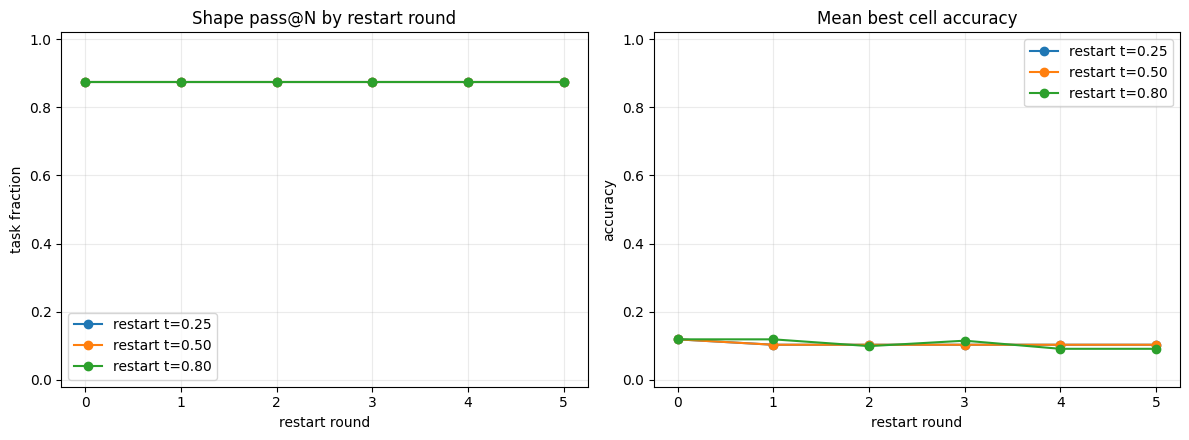

In [13]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), squeeze=False)
metric_axes = axes[0]
task_count = len(get_conditioned_panel(ACTIVE_PANEL_NAMES[0], ACTIVE_TASK_IDS)['task_ids'])

for restart_t in ACTIVE_RESTART_TIMES:
    rows = [
        row
        for row in SUMMARY_ROWS
        if row['panel'] == ACTIVE_PANEL_NAMES[0]
        and row['restart_t'] == float(restart_t)
    ]
    rounds = [row['round'] for row in rows]
    shape_rates = [row['shape_passn'] / task_count for row in rows]
    cell_rates = [
        float('nan')
        if row['mean_best_cell_accuracy'] is None
        else row['mean_best_cell_accuracy']
        for row in rows
    ]
    label = f'restart t={restart_t:.2f}'
    metric_axes[0].plot(rounds, shape_rates, marker='o', label=label)
    metric_axes[1].plot(rounds, cell_rates, marker='o', label=label)

metric_axes[0].set_title('Shape pass@N by restart round')
metric_axes[0].set_ylabel('task fraction')
metric_axes[1].set_title('Mean best cell accuracy')
metric_axes[1].set_ylabel('accuracy')
for axis in metric_axes:
    axis.set_xlabel('restart round')
    axis.set_xticks(range(MAX_RESTART_ROUNDS + 1))
    axis.set_ylim(-0.02, 1.02)
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()


## 10. Interactive per-task refinement trajectory

Choose a panel, task, generation seed, and restart time. The upper row shows
the raw VAE output after every round. The lower row shows the strictly decoded
grid, or the complete classified 30x30 canvas when PAD boundaries make the
prediction invalid.


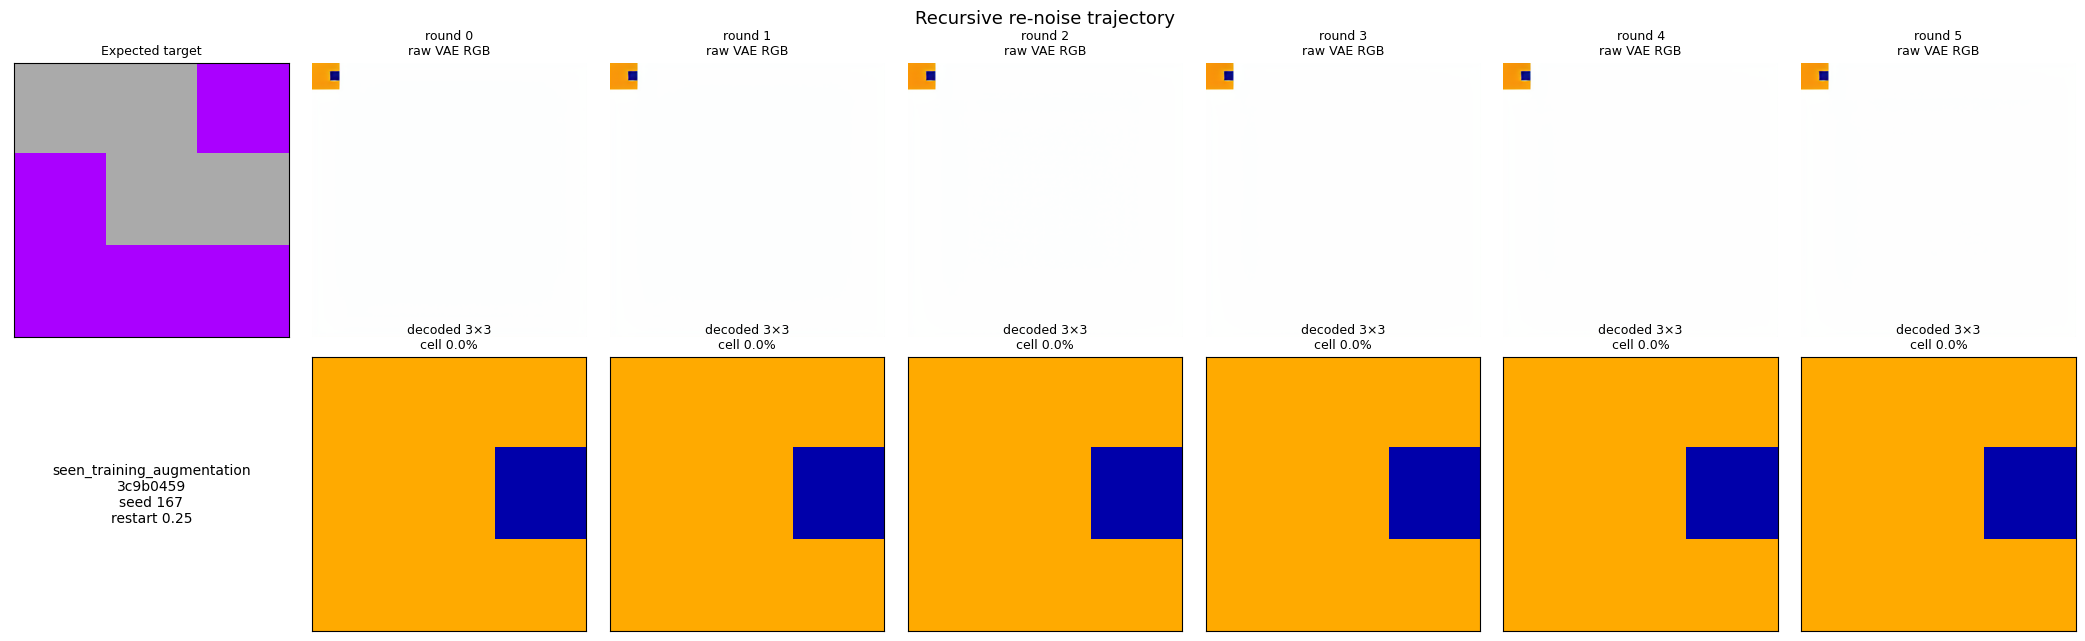

In [14]:
import numpy as np
from matplotlib.colors import ListedColormap

from diffusion_arc.arc_data import PAD_CLASS, TARGET_PALETTE_RGB

ARC_CMAP = ListedColormap(TARGET_PALETTE_RGB.numpy() / 255.0)


def show_grid(axis, values, title: str) -> None:
    array = np.asarray(values, dtype=np.int64)
    axis.imshow(
        array,
        cmap=ARC_CMAP,
        vmin=-0.5,
        vmax=PAD_CLASS + 0.5,
        interpolation='nearest',
    )
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_aspect('equal')


def plot_restart_trajectory(
    panel_name: str,
    task_id: str,
    seed: int,
    restart_t: float,
) -> None:
    entries = [
        active_restart_entry(
            panel_name,
            restart_t,
            round_index,
            seed,
        )
        for round_index in range(MAX_RESTART_ROUNDS + 1)
    ]
    task_ids = tuple(entries[0]['task_ids'])
    if task_id not in task_ids:
        raise ValueError(f'Task {task_id} is absent from the active selection')
    index = task_ids.index(task_id)
    columns = len(entries) + 1
    figure, axes = plt.subplots(
        2,
        columns,
        figsize=(3.0 * columns, 6.5),
        squeeze=False,
    )
    show_grid(axes[0, 0], entries[0]['expected_grids'][index], 'Expected target')
    axes[1, 0].axis('off')
    axes[1, 0].text(
        0.5,
        0.5,
        f'{panel_name}\n{task_id}\nseed {seed}\nrestart {restart_t:.2f}',
        ha='center',
        va='center',
    )

    for column, entry in enumerate(entries, start=1):
        round_index = column - 1
        rgb = entry['rgb_images'][index].permute(1, 2, 0).numpy()
        axes[0, column].imshow(rgb)
        axes[0, column].set_title(
            f'round {round_index}\nraw VAE RGB',
            fontsize=9,
        )
        axes[0, column].axis('off')

        prediction = entry['predictions'][index]
        diagnostic = entry['diagnostics'][index]
        if prediction.grid is None:
            decoded = entry['class_canvases'][index].numpy()
            decoded_label = f'invalid: {prediction.invalid_reason}'
        else:
            decoded = prediction.grid
            decoded_label = f'decoded {prediction.height}×{prediction.width}'
        if diagnostic.exact_grid:
            metric_label = 'EXACT'
        elif diagnostic.cell_accuracy is not None:
            metric_label = f'cell {100 * diagnostic.cell_accuracy:.1f}%'
        elif diagnostic.shape_match:
            metric_label = 'shape match'
        else:
            metric_label = 'shape mismatch'
        show_grid(
            axes[1, column],
            decoded,
            f'{decoded_label}\n{metric_label}',
        )

    figure.suptitle('Recursive re-noise trajectory', fontsize=13)
    plt.tight_layout()
    plt.show()


DISPLAY_PANEL = ACTIVE_PANEL_NAMES[0]
DISPLAY_TASK_ID = (
    ACTIVE_TASK_IDS[0]
    if ACTIVE_TASK_IDS
    else PANEL_PROMPTS[DISPLAY_PANEL]['task_ids'][0]
)
DISPLAY_SEED = ACTIVE_GENERATION_SEEDS[0]
DISPLAY_RESTART_T = ACTIVE_RESTART_TIMES[0]
plot_restart_trajectory(
    DISPLAY_PANEL,
    DISPLAY_TASK_ID,
    DISPLAY_SEED,
    DISPLAY_RESTART_T,
)


In [15]:
# Set to True and rerun to display every active task for one restart branch.
DISPLAY_ALL_TASKS = False
if DISPLAY_ALL_TASKS:
    conditioned = get_conditioned_panel(DISPLAY_PANEL, ACTIVE_TASK_IDS)
    for task_id in conditioned['task_ids']:
        plot_restart_trajectory(
            DISPLAY_PANEL,
            task_id,
            DISPLAY_SEED,
            DISPLAY_RESTART_T,
        )
else:
    print('Set DISPLAY_ALL_TASKS = True to render the full active panel.')


Set DISPLAY_ALL_TASKS = True to render the full active panel.


## 11. Optional durable result export

This saves the shared baselines and all restart rounds as a compact report plus
one PNG per sample. It deliberately performs no explicit Modal Volume commit;
ordinary writes to the mounted path are used.


In [16]:
from PIL import Image


def diagnostic_payload(diagnostic) -> dict[str, object]:
    return {
        'prediction_valid': diagnostic.prediction_valid,
        'invalid_reason': diagnostic.invalid_reason,
        'predicted_shape': diagnostic.predicted_shape,
        'expected_shape': diagnostic.expected_shape,
        'shape_match': diagnostic.shape_match,
        'cell_accuracy': diagnostic.cell_accuracy,
        'exact_grid': diagnostic.exact_grid,
    }


def serialize_entry(
    entry: dict[str, object],
    *,
    images_root: Path,
) -> dict[str, object]:
    restart_label = (
        'baseline'
        if entry['round_index'] == 0
        else f'restart-{entry["restart_t"]:.2f}-round-{entry["round_index"]}'
    )
    samples = []
    for index, task_id in enumerate(entry['task_ids']):
        filename = (
            f'{entry["panel_name"]}-{restart_label}-'
            f'seed-{entry["seed"]}-{index:02d}-{task_id}.png'
        )
        image = entry['rgb_images'][index].permute(1, 2, 0).numpy()
        Image.fromarray(image).save(images_root / filename)
        prediction = entry['predictions'][index]
        samples.append({
            'task_id': task_id,
            'key': entry['keys'][index],
            'expected_grid': entry['expected_grids'][index],
            'prediction': prediction.grid,
            'image': str((images_root / filename).relative_to(OUTPUT_ROOT)),
            'diagnostic': diagnostic_payload(entry['diagnostics'][index]),
        })
    return {
        'panel': entry['panel_name'],
        'base_num_steps': entry['base_num_steps'],
        'seed': entry['seed'],
        'restart_t': entry['restart_t'],
        'round': entry['round_index'],
        'restart_noise_seed': entry.get('restart_noise_seed'),
        'segment_intervals': entry['segment_intervals'],
        'cumulative_transformer_evaluations': (
            entry['cumulative_transformer_evaluations']
        ),
        'seconds': entry['seconds'],
        'cumulative_seconds': entry['cumulative_seconds'],
        'memory': entry['memory'],
        'samples': samples,
    }


def save_active_results() -> Path:
    images_root = OUTPUT_ROOT / 'generated_images'
    images_root.mkdir(parents=True, exist_ok=True)
    serialized_runs = []

    for panel_name in ACTIVE_PANEL_NAMES:
        conditioned = get_conditioned_panel(panel_name, ACTIVE_TASK_IDS)
        chosen_task_ids = tuple(conditioned['task_ids'])
        for seed in ACTIVE_GENERATION_SEEDS:
            base_entry = BASELINE_CACHE[
                baseline_cache_key(panel_name, chosen_task_ids, seed)
            ]
            serialized_runs.append(
                serialize_entry(base_entry, images_root=images_root)
            )
            for restart_t in ACTIVE_RESTART_TIMES:
                for round_index in range(1, MAX_RESTART_ROUNDS + 1):
                    entry = RESTART_CACHE[
                        restart_cache_key(
                            panel_name,
                            chosen_task_ids,
                            restart_t,
                            round_index,
                            seed,
                        )
                    ]
                    serialized_runs.append(
                        serialize_entry(entry, images_root=images_root)
                    )

    report = {
        'schema_version': 1,
        'status': 'COMPLETE',
        'evaluation_id': EVALUATION_ID,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'question': (
            'Can recursive partial re-noising improve outputs from the saved '
            'overfitting checkpoint without retraining?'
        ),
        'training_run_id': TRAINING_RUN_ID,
        'training_report_status': training_report['status'],
        'checkpoint': CHECKPOINT_MANIFEST,
        'source_revision': RESOLVED_SOURCE_COMMIT,
        'environment': {
            'python': platform.python_version(),
            'torch': torch.__version__,
            'cuda_runtime': torch.version.cuda,
            'gpu_name': properties.name,
            'gpu_vram_gib': gpu_vram_gib,
            'packages': {
                name: installed_version(name) for name in PINNED_PACKAGES
            },
        },
        'configuration': {
            'panels': ACTIVE_PANEL_NAMES,
            'task_ids': ACTIVE_TASK_IDS or TASK_IDS,
            'base_num_steps': BASE_NUM_STEPS,
            'restart_times': ACTIVE_RESTART_TIMES,
            'maximum_restart_rounds': MAX_RESTART_ROUNDS,
            'generation_seeds': ACTIVE_GENERATION_SEEDS,
            'matched_restart_noise_across_times': True,
            'image_sequence_length': IMAGE_SEQUENCE_LENGTH,
        },
        'summary': build_summary_rows(),
        'runs': serialized_runs,
    }
    report_path = OUTPUT_ROOT / 'report.json'
    temporary = report_path.with_suffix('.json.tmp')
    temporary.write_text(
        json.dumps(report, indent=2, sort_keys=True, allow_nan=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(report_path)
    if hasattr(os, 'sync'):
        os.sync()
    return report_path


if SAVE_RESULTS:
    SAVED_REPORT_PATH = save_active_results()
    print('Saved restart report:', SAVED_REPORT_PATH)
else:
    print('SAVE_RESULTS is False; results remain in the notebook cache only.')


Saved restart report: /mnt/diffusion-arc-models/results/single-gpu-overfitting-pilot/20260825T150620231361Z/restart-sampling-comparisons/20260825T203225808608Z/report.json


## 12. Interpretation boundary and next decision

- If cell accuracy rises consistently over rounds at `t=0.25`, the model can
  make local corrections when initialized near one of its own outputs.
- If only `t=0.50` improves, larger trajectory changes are needed; compare the
  gain against its additional transformer evaluations.
- `t=0.80` is a near-resampling control: improvement there without stability
  at lower restart times indicates exploration rather than refinement.
- If shape or cell accuracy degrades monotonically, self-generated latents are
  likely poor restart anchors for this checkpoint.
- If outputs barely change across all restart times, sampler recursion cannot
  compensate for weak or ignored NVARC conditioning.
- This uses known targets only for post-hoc diagnostics. It performs no
  target-based stopping, candidate selection, test-time augmentation, voting,
  task-specific parameter update, or training.
- This training-task-only comparison is diagnostic evidence, not an ARC
  validation result and not evidence of generalization.
